# Handwritten Digit Recognition using a Convolutional Neural Network (CNN)

**Dataset:** MNIST (60,000 training images + 10,000 test images, 28 x 28 grayscale, digits 0-9)
**Framework:** TensorFlow / Keras

In this notebook we build a CNN that reads an image of a handwritten digit and predicts which digit (0-9) it is.

**What we will do, step by step**
1. Import libraries and fix the random seed (reproducibility)
2. Load and explore the MNIST dataset
3. Split the data into train / validation / test sets
4. Preprocess the images (normalize, reshape, one-hot encode)
5. Build, compile and train the CNN (with callbacks)
6. Evaluate it: graphs, confusion matrix, classification report
7. Look at sample predictions and analyse the mistakes
8. Export the model, class labels and preprocessing settings for the FastAPI backend (Phase 4)

**How to run:** run the cells from top to bottom (Runtime -> Run all in Colab, or Kernel -> Restart & Run All in Jupyter). Every cell depends on the ones above it.

## 1. Importing Libraries and Setting the Random Seed

We use `numpy` and `pandas` for data handling, `matplotlib` and `seaborn` for plots, `scikit-learn` for splitting the data and for the evaluation metrics, and `TensorFlow/Keras` for the CNN.

A **random seed** makes the notebook reproducible: weight initialisation, shuffling and the train/validation split will be the same every time. (On a GPU a few TensorFlow operations are still slightly non-deterministic, so tiny differences between runs are possible.)

In [1]:
import os
import json
import shutil
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score

from PIL import Image, ImageOps

In [2]:
# Reproducibility: one seed for Python, NumPy and TensorFlow
SEED = 42
keras.utils.set_random_seed(SEED)

# Project settings (kept in one place so we do not repeat numbers everywhere)
IMG_SIZE = 28           # MNIST images are 28 x 28
NUM_CLASSES = 10        # digits 0 to 9
VAL_SIZE = 6000         # validation images taken out of the 60,000 training images
BATCH_SIZE = 128
EPOCHS = 15             # upper limit, EarlyStopping may stop sooner
EXPORT_DIR = "exported_model"   # everything for the FastAPI app is saved here
CHECKPOINT_DIR = "checkpoints"

os.makedirs(EXPORT_DIR, exist_ok=True)
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

print("Python     :", platform.python_version())
print("TensorFlow :", tf.__version__)
print("Keras      :", keras.__version__)

Python     : 3.13.18
TensorFlow : 2.21.0
Keras      : 3.13.2


We print the library versions on purpose. The saved model must later be loaded in the FastAPI backend, and it is safest to use the **same TensorFlow/Keras version** there. We will also store these versions in the exported configuration file.

## 2. Loading the MNIST Dataset

Keras can download MNIST for us, so no manual CSV files are needed and the notebook works on any machine with internet access. The function returns the **official** split: 60,000 images for training and 10,000 for testing. The images are NumPy arrays with pixel values from 0 (black) to 255 (white).

In [3]:
(X_train_full, y_train_full), (X_test, y_test) = keras.datasets.mnist.load_data()

print("Training images :", X_train_full.shape, X_train_full.dtype)
print("Training labels :", y_train_full.shape)
print("Test images     :", X_test.shape)
print("Test labels     :", y_test.shape)
print("Pixel value range:", X_train_full.min(), "to", X_train_full.max())
print("Missing values   :", np.isnan(X_train_full.astype("float32")).sum())

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training images : (60000, 28, 28) uint8
Training labels : (60000,)
Test images     : (10000, 28, 28)
Test labels     : (10000,)
Pixel value range: 0 to 255
Missing values   : 0


## 3. Data Exploration

### 3.1 Sample images
First we look at one example of every digit, and then at 25 random training images, to get a feeling for the handwriting style.

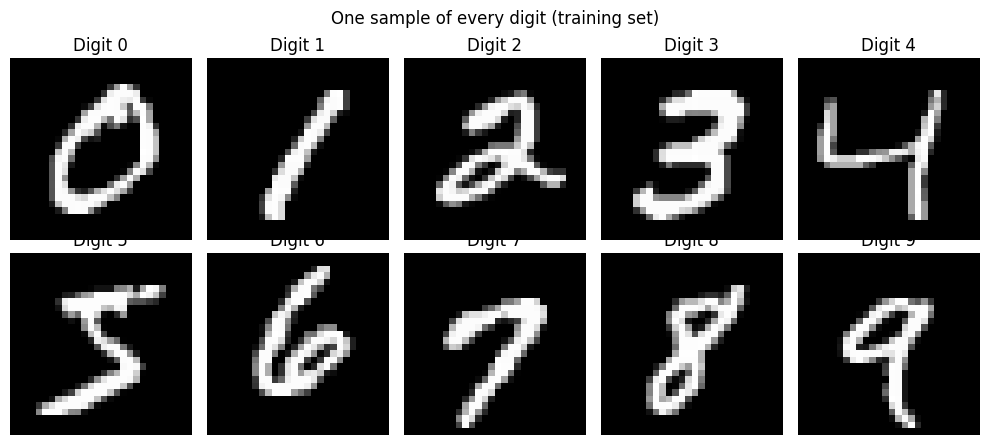

In [4]:
# One example of each digit
fig, axes = plt.subplots(2, 5, figsize=(10, 4.5))
for digit, ax in zip(range(NUM_CLASSES), axes.ravel()):
    first_index = np.where(y_train_full == digit)[0][0]
    ax.imshow(X_train_full[first_index], cmap="gray")
    ax.set_title(f"Digit {digit}")
    ax.axis("off")
plt.suptitle("One sample of every digit (training set)")
plt.tight_layout()
plt.show()

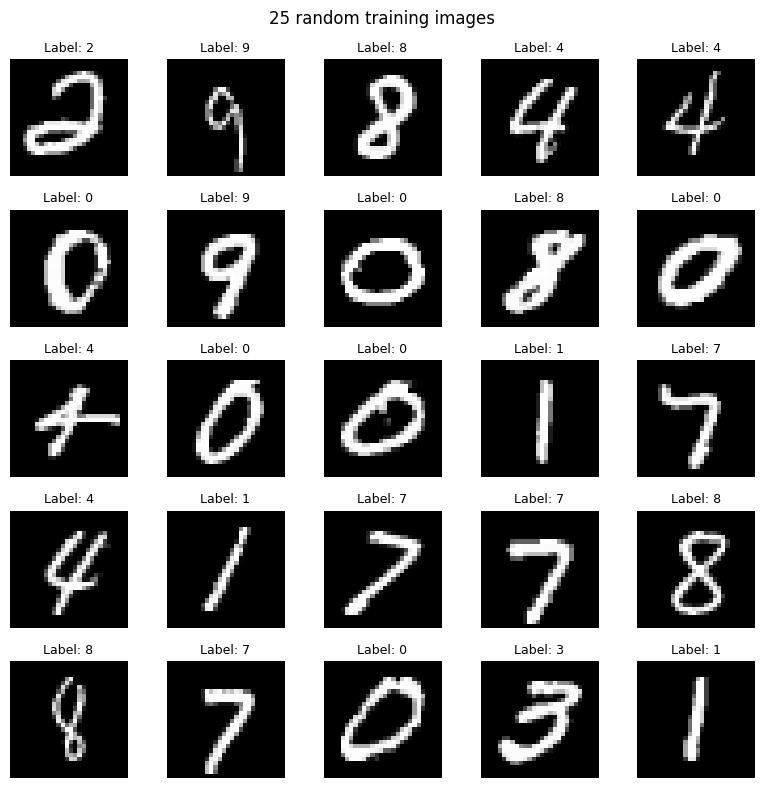

In [5]:
# 25 random training images
rng = np.random.default_rng(SEED)
random_idx = rng.choice(len(X_train_full), 25, replace=False)

plt.figure(figsize=(8, 8))
for i, idx in enumerate(random_idx):
    plt.subplot(5, 5, i + 1)
    plt.imshow(X_train_full[idx], cmap="gray")
    plt.title(f"Label: {y_train_full[idx]}", fontsize=9)
    plt.axis("off")
plt.suptitle("25 random training images")
plt.tight_layout()
plt.show()

**Observation:** the digits are white on a black background, roughly centered, and every writer has a different style (for example, different ways of writing 1, 4 and 7). The CNN has to learn what stays the same across all these styles.

### 3.2 Class distribution
A model can become biased if some classes have many more images than others. Let us count the images per digit.

,train_images,test_images
digit,,
0,5923,980
1,6742,1135
2,5958,1032
3,6131,1010
4,5842,982
5,5421,892
6,5918,958
7,6265,1028
8,5851,974


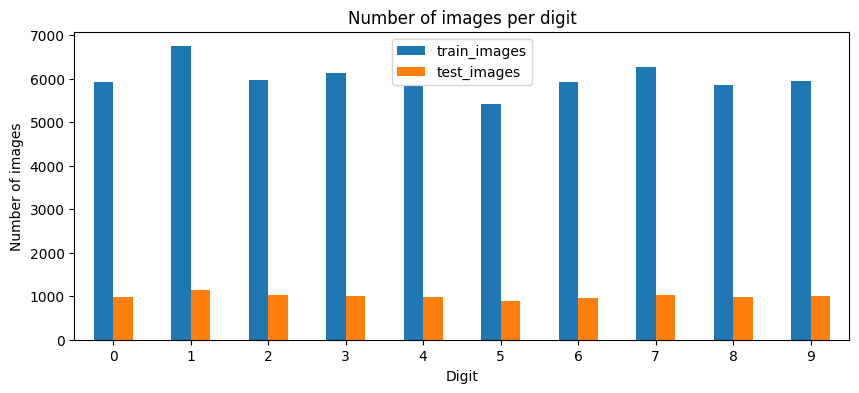

In [6]:
train_counts = pd.Series(y_train_full).value_counts().sort_index()
test_counts = pd.Series(y_test).value_counts().sort_index()

count_table = pd.DataFrame({"train_images": train_counts, "test_images": test_counts})
count_table.index.name = "digit"
display(count_table)

count_table.plot(kind="bar", figsize=(10, 4))
plt.title("Number of images per digit")
plt.xlabel("Digit")
plt.ylabel("Number of images")
plt.xticks(rotation=0)
plt.show()

**Observation:** all ten digits have a similar number of images. The data is not perfectly balanced (digit 1 has the most images and digit 5 the fewest in the training set) but the differences are small, so we do not need class weights or resampling. We will still keep an eye on per-class results during evaluation.

## 4. Train / Validation / Test Split

We use three separate sets:

| Set | Where it comes from | Purpose |
|---|---|---|
| **Train** | 54,000 of the 60,000 training images | the model learns from these |
| **Validation** | 6,000 of the 60,000 training images | used during training to watch for overfitting, to stop early and to save the best model |
| **Test** | the official 10,000 test images | used **only once at the end** for the final score |

**Preventing data leakage**
- The split is done **before** any preprocessing.
- The test set is never used for training, early stopping or choosing the model.
- `stratify=y_train_full` keeps the digit proportions the same in the train and validation sets.
- Our only scaling step is dividing by 255, a fixed number, so no statistics are copied from the validation or test data.

**Small note:** the 60,000 training images come from about 250 writers, so the same writers appear in both our train and validation sets. The official test set was written by different people. Because of this, the validation score can be a little more optimistic than the test score.

In [7]:
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full,
    test_size=VAL_SIZE,
    stratify=y_train_full,
    random_state=SEED,
)

print("Train      :", X_train.shape, y_train.shape)
print("Validation :", X_val.shape, y_val.shape)
print("Test       :", X_test.shape, y_test.shape)

Train      : (54000, 28, 28) (54000,)
Validation : (6000, 28, 28) (6000,)
Test       : (10000, 28, 28) (10000,)


In [8]:
# Check that the class proportions (in %) are similar in all three sets
proportions = pd.DataFrame({
    "train_%": pd.Series(y_train).value_counts(normalize=True).sort_index() * 100,
    "validation_%": pd.Series(y_val).value_counts(normalize=True).sort_index() * 100,
    "test_%": pd.Series(y_test).value_counts(normalize=True).sort_index() * 100,
}).round(2)
proportions.index.name = "digit"
display(proportions)

,train_%,validation_%,test_%
digit,,,
0,9.87,9.87,9.80
1,11.24,11.23,11.35
2,9.93,9.93,10.32
3,10.22,10.22,10.10
4,9.74,9.73,9.82
5,9.04,9.03,8.92
6,9.86,9.87,9.58
7,10.44,10.45,10.28
8,9.75,9.75,9.74


## 5. Preprocessing

Three steps are needed before the images go into the CNN:

1. **Normalization:** convert pixel values from 0-255 to 0-1 (`/ 255.0`). Small input values make training faster and more stable.
2. **Reshaping:** a CNN expects images in the shape `(height, width, channels)`. MNIST is grayscale, so we add one channel: `(28, 28)` becomes `(28, 28, 1)`.
3. **Label encoding:** the labels (0-9) are converted to one-hot vectors, for example `3 -> [0,0,0,1,0,0,0,0,0,0]`. This matches the 10 softmax outputs and the `categorical_crossentropy` loss.

These exact steps must be repeated in the FastAPI backend, so we will save them in a configuration file later.

In [9]:
def preprocess_images(images):
    # uint8 images (N, 28, 28) -> float32 images (N, 28, 28, 1) scaled to 0-1
    images = images.astype("float32") / 255.0
    return images.reshape(-1, IMG_SIZE, IMG_SIZE, 1)

X_train_cnn = preprocess_images(X_train)
X_val_cnn = preprocess_images(X_val)
X_test_cnn = preprocess_images(X_test)

y_train_cat = to_categorical(y_train, NUM_CLASSES)
y_val_cat = to_categorical(y_val, NUM_CLASSES)
y_test_cat = to_categorical(y_test, NUM_CLASSES)

print("X_train_cnn:", X_train_cnn.shape, X_train_cnn.dtype)
print("Pixel range after scaling:", X_train_cnn.min(), "to", X_train_cnn.max())
print("y_train_cat:", y_train_cat.shape)
print("Label of first training image:", y_train[0], "->", y_train_cat[0])

X_train_cnn: (54000, 28, 28, 1) float32
Pixel range after scaling: 0.0 to 1.0
y_train_cat: (54000, 10)
Label of first training image: 2 -> [0. 0. 1. 0. 0. 0. 0. 0. 0. 0.]


## 6. Building the CNN

The architecture is a small, standard CNN. Each part has a job:

| Layer | What it does |
|---|---|
| `Conv2D(32, 3x3)` + ReLU | learns 32 small filters that detect simple patterns such as edges and strokes |
| `MaxPooling2D(2x2)` | halves the image size, keeps the strongest responses, adds a little tolerance to shifts |
| `Conv2D(64, 3x3)` + ReLU | combines simple patterns into larger shapes (curves, loops, crossings) |
| `MaxPooling2D(2x2)` | shrinks the feature maps again |
| `Flatten` | turns the feature maps into one long vector |
| `Dense(128)` + ReLU | combines all features to make a decision |
| `Dropout(0.5)` | randomly switches off half of these neurons during training so the model does not memorise the training images |
| `Dense(10)` + softmax | outputs 10 probabilities (one per digit) that add up to 1 |

In [10]:
model = keras.Sequential([
    keras.Input(shape=(IMG_SIZE, IMG_SIZE, 1)),

    layers.Conv2D(32, kernel_size=(3, 3), activation="relu"),
    layers.MaxPooling2D(pool_size=(2, 2)),

    layers.Conv2D(64, kernel_size=(3, 3), activation="relu"),
    layers.MaxPooling2D(pool_size=(2, 2)),

    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(NUM_CLASSES, activation="softmax"),
], name="digit_cnn")

model.summary()

Model: "digit_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

**Reading the model summary**

- A 3x3 filter without padding removes 2 pixels in each direction, so the image sizes go `28 -> 26 -> 13 -> 11 -> 5`.
- After the last pooling layer we have `5 x 5 x 64 = 1600` values, which is what `Flatten` outputs.
- Parameter counts you can verify by hand: first Conv layer `3*3*1*32 + 32 = 320`, second Conv layer `3*3*32*64 + 64 = 18,496`, first Dense layer `1600*128 + 128 = 204,928`, output layer `128*10 + 10 = 1,290`.
- Together this should be **225,034** parameters, a small model that is quick to train and easy to deploy.

## 7. Compiling the Model

- **Optimizer: Adam** adapts the learning rate for every weight and works well without much tuning.
- **Loss: categorical cross-entropy** is the standard loss for multi-class classification with one-hot labels.
- **Metric: accuracy**, the fraction of images classified correctly.

In [11]:
model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)

## 8. Callbacks and Training

Callbacks are small helpers that run automatically during training:

- **EarlyStopping** stops training when the validation loss has not improved for 3 epochs in a row, and `restore_best_weights=True` puts the best weights back. This protects us from overfitting and saves time.
- **ModelCheckpoint** saves the model to disk every time the validation loss reaches a new best value, so a crash or disconnect will not lose our progress.

We train with a batch size of 128 for at most 15 epochs. The validation set is used to monitor training. **The test set is not used here.**

In [12]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1,
)

checkpoint = ModelCheckpoint(
    filepath=os.path.join(CHECKPOINT_DIR, "best_digit_cnn.keras"),
    monitor="val_loss",
    save_best_only=True,
    verbose=1,
)

In [13]:
history = model.fit(
    X_train_cnn, y_train_cat,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_data=(X_val_cnn, y_val_cat),
    callbacks=[early_stop, checkpoint],
    verbose=1,
)

Epoch 1/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 0s 101ms/step - accuracy: 0.8087 - loss: 0.6260
Epoch 1: val_loss improved from None to 0.09634, saving model to checkpoints/best_digit_cnn.keras

Epoch 1: finished saving model to checkpoints/best_digit_cnn.keras
422/422 ━━━━━━━━━━━━━━━━━━━━ 48s 105ms/step - accuracy: 0.9095 - loss: 0.3024 - val_accuracy: 0.9720 - val_loss: 0.0963
Epoch 2/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 0s 101ms/step - accuracy: 0.9669 - loss: 0.1094
Epoch 2: val_loss improved from 0.09634 to 0.05690, saving model to checkpoints/best_digit_cnn.keras

Epoch 2: finished saving model to checkpoints/best_digit_cnn.keras
422/422 ━━━━━━━━━━━━━━━━━━━━ 81s 104ms/step - accuracy: 0.9709 - loss: 0.0979 - val_accuracy: 0.9843 - val_loss: 0.0569
Epoch 3/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 0s 101ms/step - accuracy: 0.9766 - loss: 0.0787
Epoch 3: val_loss improved from 0.05690 to 0.05412, saving model to checkpoints/best_digit_cnn.keras

Epoch 3: finished saving model to checkpoints/best_digit_cn

## 9. Training Curves

We plot accuracy and loss for the training set and the validation set after every epoch.

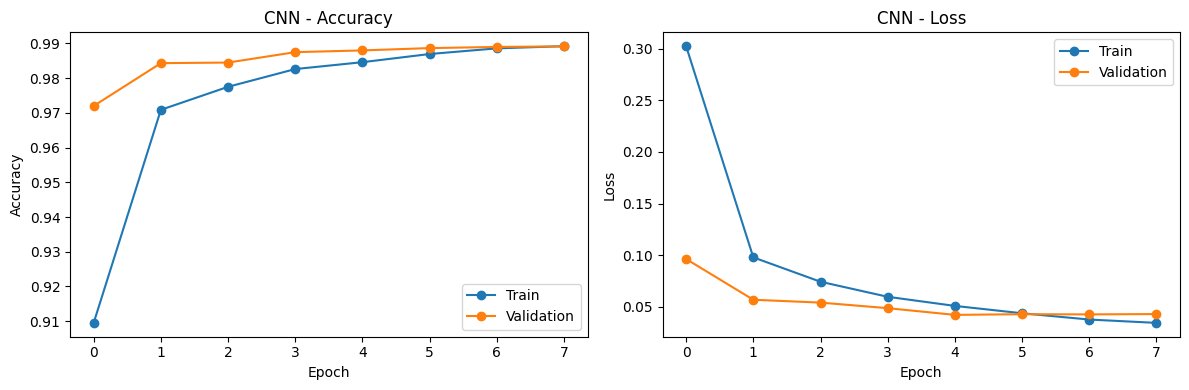

Epochs run                  : 8
Best epoch (lowest val loss): 5
Validation accuracy at best epoch: 0.988
Validation loss at best epoch    : 0.0422


In [14]:
def plot_training(history, title):
    plt.figure(figsize=(12, 4))

    plt.subplot(1, 2, 1)
    plt.plot(history.history["accuracy"], marker="o", label="Train")
    plt.plot(history.history["val_accuracy"], marker="o", label="Validation")
    plt.title(f"{title} - Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(history.history["loss"], marker="o", label="Train")
    plt.plot(history.history["val_loss"], marker="o", label="Validation")
    plt.title(f"{title} - Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()

    plt.tight_layout()
    plt.show()

plot_training(history, "CNN")

best_epoch = int(np.argmin(history.history["val_loss"])) + 1
epochs_run = len(history.history["loss"])
print("Epochs run                  :", epochs_run)
print("Best epoch (lowest val loss):", best_epoch)
print("Validation accuracy at best epoch:", round(history.history["val_accuracy"][best_epoch - 1], 4))
print("Validation loss at best epoch    :", round(history.history["val_loss"][best_epoch - 1], 4))

**How to read these graphs**

- **Accuracy curves:** both lines should rise quickly in the first epochs and then flatten out.
- **Loss curves:** both lines should fall. Loss measures how confident *and* correct the predictions are, so it is more sensitive than accuracy.
- **Healthy training:** the training and validation lines stay close to each other.
- **Overfitting:** if the training loss keeps falling while the validation loss starts to rise, the model is memorising the training images. This is the point where EarlyStopping stops training and restores the best epoch.
- **Why validation can look better than training in early epochs:** Dropout is active while training but switched off when validating, so the training numbers are measured on a handicapped network.

The actual numbers for our run are printed above; we will quote them in the report.

## 10. Final Evaluation on the Test Set

Now, after all training decisions are finished, we use the 10,000 official test images **for the first time**. This score estimates how the model behaves on handwriting it has never seen.

In [15]:
test_loss, test_acc = model.evaluate(X_test_cnn, y_test_cat, verbose=0)
print(f"Test loss     : {test_loss:.4f}")
print(f"Test accuracy : {test_acc * 100:.2f}%")

# Predicted probabilities (10 per image) and predicted digits
y_prob = model.predict(X_test_cnn, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

print("Check with sklearn:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")

Test loss     : 0.0277
Test accuracy : 98.96%
Check with sklearn: 98.96 %


### 10.1 Confusion matrix
Each row is the **true** digit and each column is the **predicted** digit. Numbers on the diagonal are correct predictions; every number off the diagonal is a mistake (for example, row 4 / column 9 counts the 4s that were predicted as 9).

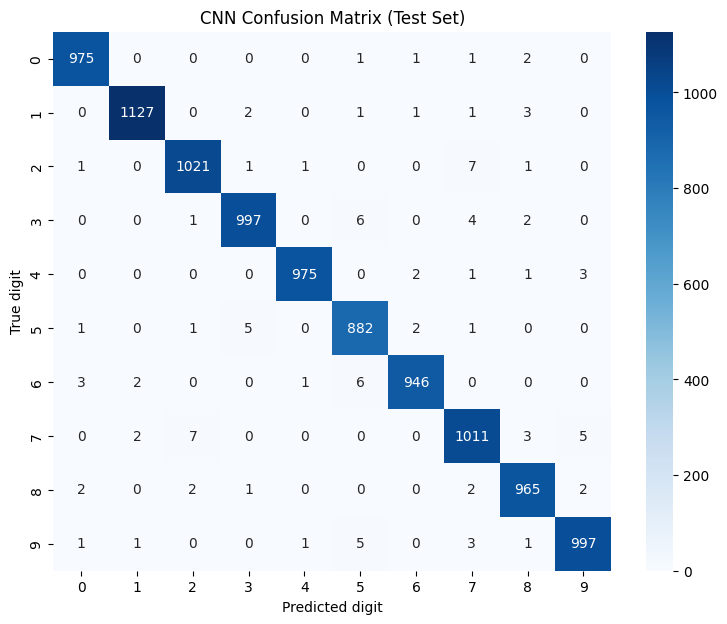

In [16]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=range(NUM_CLASSES), yticklabels=range(NUM_CLASSES))
plt.title("CNN Confusion Matrix (Test Set)")
plt.xlabel("Predicted digit")
plt.ylabel("True digit")
plt.show()

**How to read it:** a strong model has a dark diagonal and almost empty cells elsewhere. Look for the few off-diagonal cells that are not empty. These are the digit pairs the model confuses most, and we will examine them in the error analysis.

### 10.2 Classification report
- **Precision:** of all images the model called "7", how many really were 7?
- **Recall:** of all real 7s, how many did the model find?
- **F1-score:** the balance of precision and recall.
- **Support:** the number of test images of that digit.

In [17]:
print(classification_report(y_test, y_pred, digits=4))

              precision    recall  f1-score   support

           0     0.9919    0.9949    0.9934       980
           1     0.9956    0.9930    0.9943      1135
           2     0.9893    0.9893    0.9893      1032
           3     0.9911    0.9871    0.9891      1010
           4     0.9969    0.9929    0.9949       982
           5     0.9789    0.9888    0.9838       892
           6     0.9937    0.9875    0.9906       958
           7     0.9806    0.9835    0.9820      1028
           8     0.9867    0.9908    0.9887       974
           9     0.9901    0.9881    0.9891      1009

    accuracy                         0.9896     10000
   macro avg     0.9895    0.9896    0.9895     10000
weighted avg     0.9896    0.9896    0.9896     10000



,digit,test_images,correct,accuracy_%
0,0,980,975,99.49
1,1,1135,1127,99.30
2,2,1032,1021,98.93
3,3,1010,997,98.71
4,4,982,975,99.29
5,5,892,882,98.88
6,6,958,946,98.75
7,7,1028,1011,98.35
8,8,974,965,99.08
9,9,1009,997,98.81


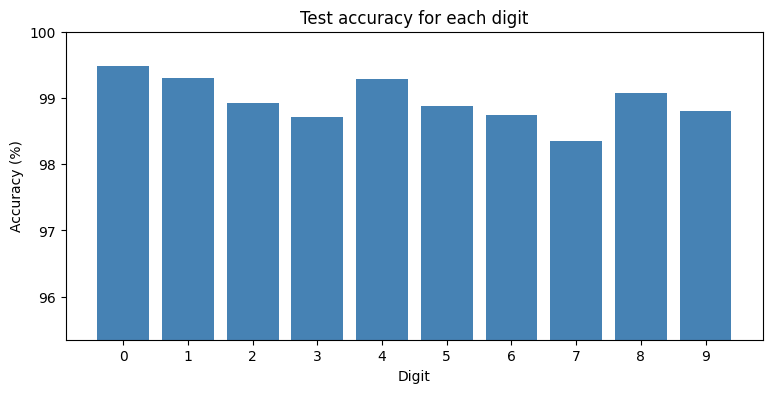

In [18]:
# Accuracy of each digit separately
per_class_df = pd.DataFrame({
    "digit": range(NUM_CLASSES),
    "test_images": cm.sum(axis=1),
    "correct": cm.diagonal(),
    "accuracy_%": (cm.diagonal() / cm.sum(axis=1) * 100).round(2),
})
display(per_class_df)

plt.figure(figsize=(9, 4))
plt.bar(per_class_df["digit"], per_class_df["accuracy_%"], color="steelblue")
plt.title("Test accuracy for each digit")
plt.xlabel("Digit")
plt.ylabel("Accuracy (%)")
plt.xticks(range(NUM_CLASSES))
plt.ylim(max(0, per_class_df["accuracy_%"].min() - 3), 100)
plt.show()

The per-digit table shows which digits are the easiest and which are the hardest for this model. We note the weakest digits and use them in the discussion section of the report.

## 11. Sample Predictions

Ten random test images with the model's prediction and its confidence (the highest softmax probability). Green titles are correct predictions and red titles are mistakes.

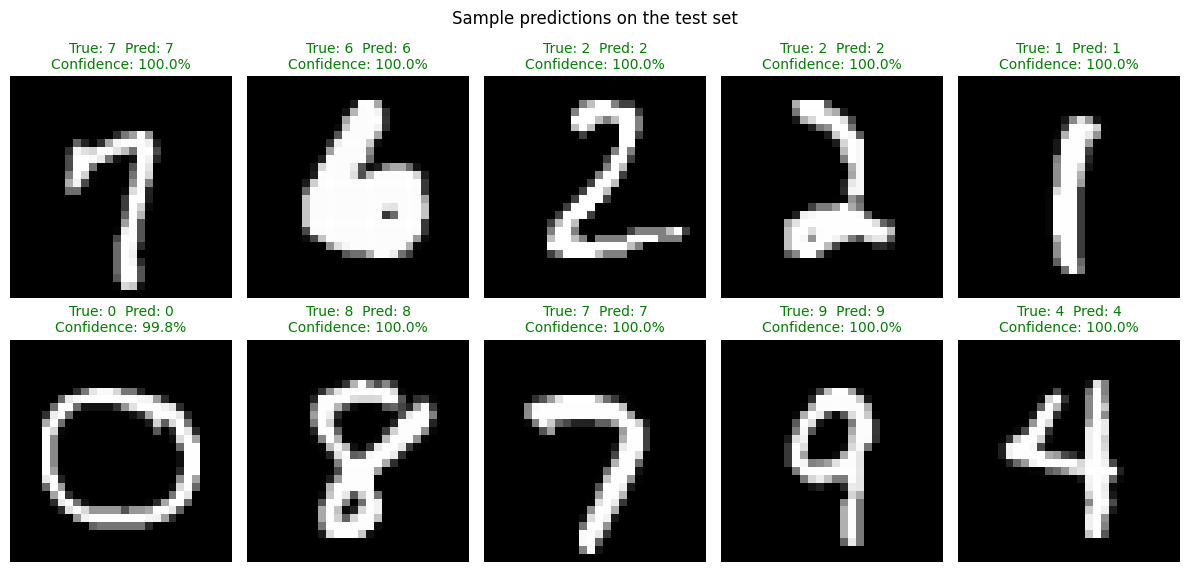

In [19]:
rng = np.random.default_rng(SEED)
sample_idx = rng.choice(len(X_test), 10, replace=False)

fig, axes = plt.subplots(2, 5, figsize=(12, 6))
for ax, i in zip(axes.ravel(), sample_idx):
    ax.imshow(X_test[i], cmap="gray")
    color = "green" if y_pred[i] == y_test[i] else "red"
    ax.set_title(f"True: {y_test[i]}  Pred: {y_pred[i]}\nConfidence: {y_prob[i].max() * 100:.1f}%",
                 color=color, fontsize=10)
    ax.axis("off")
plt.suptitle("Sample predictions on the test set")
plt.tight_layout()
plt.show()

The API we build later will return the same kind of information: the predicted digit and the probability of **every** digit. Here is that probability distribution for one test image.

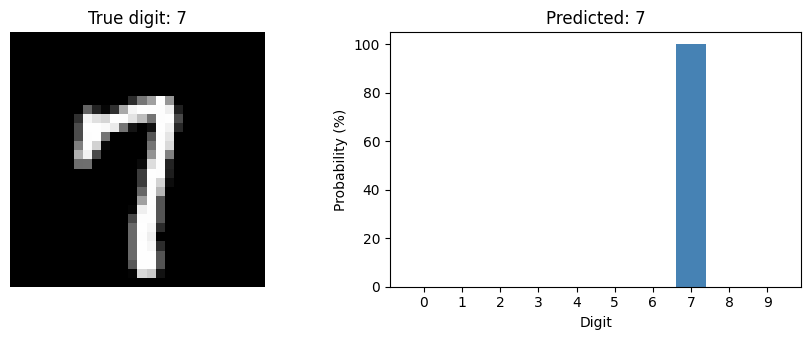

In [20]:
i = sample_idx[0]
plt.figure(figsize=(9, 3.5))

plt.subplot(1, 2, 1)
plt.imshow(X_test[i], cmap="gray")
plt.title(f"True digit: {y_test[i]}")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.bar(range(NUM_CLASSES), y_prob[i] * 100, color="steelblue")
plt.title(f"Predicted: {y_pred[i]}")
plt.xlabel("Digit")
plt.ylabel("Probability (%)")
plt.xticks(range(NUM_CLASSES))

plt.tight_layout()
plt.show()

## 12. Error Analysis

Accuracy hides *which* mistakes are made. Here we look at:
1. how many images were misclassified,
2. which digit pairs are confused most often,
3. how confident the model was when it was right and when it was wrong,
4. what the confidently-wrong images look like.

In [21]:
wrong_idx = np.where(y_pred != y_test)[0]
print("Misclassified test images:", len(wrong_idx), "out of", len(y_test))
print(f"Error rate: {len(wrong_idx) / len(y_test) * 100:.2f}%")

# Most frequently confused pairs (ignore the diagonal)
errors_only = cm.copy()
np.fill_diagonal(errors_only, 0)
pairs = [(t, p, errors_only[t, p]) for t in range(NUM_CLASSES) for p in range(NUM_CLASSES) if errors_only[t, p] > 0]
pairs = sorted(pairs, key=lambda x: x[2], reverse=True)[:5]

print("\nMost common confusions:")
for true_digit, pred_digit, count in pairs:
    print(f"  True {true_digit} predicted as {pred_digit}: {count} times")

# Confidence of correct vs wrong predictions
confidence = y_prob.max(axis=1)
print("\nAverage confidence when correct:", round(confidence[y_pred == y_test].mean() * 100, 2), "%")
if len(wrong_idx) > 0:
    print("Average confidence when wrong  :", round(confidence[wrong_idx].mean() * 100, 2), "%")

Misclassified test images: 104 out of 10000
Error rate: 1.04%

Most common confusions:
  True 2 predicted as 7: 7 times
  True 7 predicted as 2: 7 times
  True 3 predicted as 5: 6 times
  True 6 predicted as 5: 6 times
  True 5 predicted as 3: 5 times

Average confidence when correct: 99.3 %
Average confidence when wrong  : 69.4 %


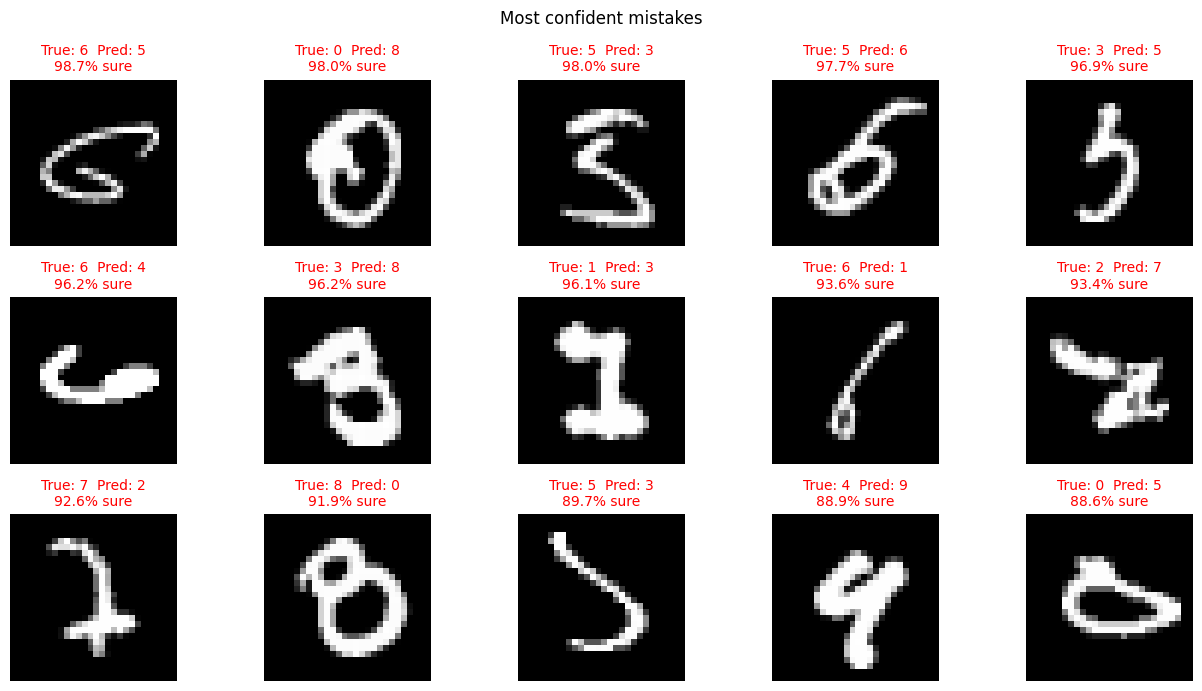

In [22]:
# Show the misclassified images where the model was MOST confident (up to 15)
if len(wrong_idx) > 0:
    order = np.argsort(-confidence[wrong_idx])
    worst = wrong_idx[order][:15]

    plt.figure(figsize=(13, 7))
    for k, i in enumerate(worst):
        plt.subplot(3, 5, k + 1)
        plt.imshow(X_test[i], cmap="gray")
        plt.title(f"True: {y_test[i]}  Pred: {y_pred[i]}\n{confidence[i] * 100:.1f}% sure", color="red", fontsize=10)
        plt.axis("off")
    plt.suptitle("Most confident mistakes")
    plt.tight_layout()
    plt.show()

**How to interpret this**

- Most mistakes are usually on images that are also hard for a person: untidy handwriting, a 4 that is almost closed like a 9, a 7 with a crossbar that looks like a 1, and so on. Compare the pictures above with the confused pairs printed before them.
- A model that is much *less* confident when it is wrong than when it is right is easier to trust. In the web app the confidence score will help the user see when a prediction is uncertain.
- Looking at a few real mistakes also shows what the model cannot do: it was trained only on clean, centered, single digits, so it will struggle with off-center, very thin or very thick strokes, or several digits in one image. These points go into the limitations part of the report.

## 13. Exporting Everything Needed for the FastAPI Backend

We save four things into the folder `exported_model/`:

| File | Purpose |
|---|---|
| `mnist_cnn.keras` | the trained model (native Keras format, used by the backend) |
| `mnist_cnn.h5` | a second copy in the older HDF5 format, kept as a fallback if the `.keras` file does not load on the server |
| `class_labels.json` | maps model output index to the digit label |
| `preprocessing_config.json` | input shape, scaling rule and library versions, so the backend can repeat the preprocessing exactly |
| `training_summary.json` | the real metrics from this run (used for the report and the model-info section of the website) |

Only the best weights are saved, because EarlyStopping already restored them.

In [23]:
# 1) Save the model
keras_path = os.path.join(EXPORT_DIR, "mnist_cnn.keras")
model.save(keras_path)
print("Saved:", keras_path)

# Older HDF5 copy as a fallback (wrapped in try/except because some versions warn or refuse)
h5_path = os.path.join(EXPORT_DIR, "mnist_cnn.h5")
try:
    model.save(h5_path)
    print("Saved:", h5_path)
except Exception as error:
    print("Could not save the .h5 copy (this is optional):", error)

Saved: exported_model/mnist_cnn.keras
Saved: exported_model/mnist_cnn.h5


In [24]:
# 2) Class labels
class_labels = {
    "classes": [str(d) for d in range(NUM_CLASSES)],
    "index_to_label": {str(d): str(d) for d in range(NUM_CLASSES)},
}
with open(os.path.join(EXPORT_DIR, "class_labels.json"), "w") as f:
    json.dump(class_labels, f, indent=2)

# 3) Preprocessing configuration (the contract for the backend)
preprocessing_config = {
    "dataset": "MNIST (keras.datasets.mnist)",
    "model_file": "mnist_cnn.keras",
    "input_shape": [IMG_SIZE, IMG_SIZE, 1],
    "image_size": IMG_SIZE,
    "color_mode": "grayscale",
    "pixel_dtype": "float32",
    "pixel_scale": 255.0,
    "normalization": "pixel / 255.0 -> values between 0 and 1",
    "digit_color": "white digit (255) on black background (0), same as MNIST",
    "batch_shape": [None, IMG_SIZE, IMG_SIZE, 1],
    "num_classes": NUM_CLASSES,
    "output": "10 softmax probabilities, output index = digit",
    "random_seed": SEED,
    "split": {
        "train": int(len(X_train)),
        "validation": int(len(X_val)),
        "test": int(len(X_test)),
        "stratified": True,
    },
    "versions": {
        "python": platform.python_version(),
        "tensorflow": tf.__version__,
        "keras": keras.__version__,
        "numpy": np.__version__,
    },
}
with open(os.path.join(EXPORT_DIR, "preprocessing_config.json"), "w") as f:
    json.dump(preprocessing_config, f, indent=2)

# 4) Training summary with the REAL numbers of this run
training_summary = {
    "test_accuracy": float(test_acc),
    "test_loss": float(test_loss),
    "best_epoch": int(best_epoch),
    "epochs_run": int(epochs_run),
    "validation_accuracy_at_best_epoch": float(history.history["val_accuracy"][best_epoch - 1]),
    "validation_loss_at_best_epoch": float(history.history["val_loss"][best_epoch - 1]),
    "total_parameters": int(model.count_params()),
    "batch_size": BATCH_SIZE,
    "optimizer": "adam",
    "loss": "categorical_crossentropy",
}
with open(os.path.join(EXPORT_DIR, "training_summary.json"), "w") as f:
    json.dump(training_summary, f, indent=2)

print(json.dumps(training_summary, indent=2))
print("\nFiles in", EXPORT_DIR, ":", os.listdir(EXPORT_DIR))

{
  "test_accuracy": 0.9896000027656555,
  "test_loss": 0.027695773169398308,
  "best_epoch": 5,
  "epochs_run": 8,
  "validation_accuracy_at_best_epoch": 0.9879999756813049,
  "validation_loss_at_best_epoch": 0.04224565997719765,
  "total_parameters": 225034,
  "batch_size": 128,
  "optimizer": "adam",
  "loss": "categorical_crossentropy"
}

Files in exported_model : ['preprocessing_config.json', 'class_labels.json', 'training_summary.json', 'mnist_cnn.keras', 'mnist_cnn.h5']


## 14. Checking the Exported Model

Before we move on we must be sure that the saved files really work. We do two checks:

1. **Reload check:** load the saved `.keras` file and confirm it gives the same predictions as the model in memory.
2. **Inference-style check:** write the preprocessing as a function that takes a normal image (like an uploaded file) and returns the tensor the model needs. This function is the starting point for the FastAPI backend.

In [25]:
# Check 1: reload the model from disk
loaded_model = keras.models.load_model(os.path.join(EXPORT_DIR, "mnist_cnn.keras"))
loaded_prob = loaded_model.predict(X_test_cnn, verbose=0)

print("Largest difference in predicted probabilities:", float(np.abs(loaded_prob - y_prob).max()))
print("Reloaded model test accuracy:", round(accuracy_score(y_test, np.argmax(loaded_prob, axis=1)) * 100, 2), "%")

Largest difference in predicted probabilities: 0.0
Reloaded model test accuracy: 98.96 %


In [26]:
# Check 2: an inference-style preprocessing function (PIL image in, model tensor out)
def preprocess_image_for_model(image, invert=False):
    # PIL image -> array of shape (1, 28, 28, 1) scaled to 0-1
    img = image.convert("L")                       # grayscale
    if invert:                                     # dark ink on a white page -> white digit on black
        img = ImageOps.invert(img)
    img = img.resize((IMG_SIZE, IMG_SIZE), Image.LANCZOS)
    arr = np.array(img, dtype="float32") / 255.0   # same scaling as training
    return arr.reshape(1, IMG_SIZE, IMG_SIZE, 1)   # batch, height, width, channel

# Simulate uploaded pictures: take 100 test digits, enlarge them to 280 x 280 and
# invert them (black digit on white paper), then run them through the function.
agree = 0
n_check = 100
for i in range(n_check):
    big = Image.fromarray(X_test[i]).resize((280, 280), Image.BICUBIC)
    paper_style = ImageOps.invert(big)
    tensor = preprocess_image_for_model(paper_style, invert=True)
    pred_from_image = int(np.argmax(loaded_model.predict(tensor, verbose=0)))
    agree += int(pred_from_image == y_pred[i])

print(f"Predictions through the image pipeline agree with direct predictions on {agree} of {n_check} images")

Predictions through the image pipeline agree with direct predictions on 100 of 100 images


This pipeline reproduces the training format (grayscale, 28 x 28, white digit on black, divided by 255, shape `(1, 28, 28, 1)`). Small differences from direct prediction are normal because the image is resized up and down.

**Important limitation (handled in Phases 4 and 5):** these test digits were created from MNIST, so they are already centered and sized like MNIST. Real photos and canvas drawings are not. For them the backend and the drawing canvas will also need MNIST-style centering and size normalization, and we will test that carefully there.

In [27]:
# Pack the export folder into one zip file (easy to download and to put into the project)
shutil.make_archive("exported_model", "zip", EXPORT_DIR)
print("Created exported_model.zip")

# If this notebook runs in Google Colab, start the download automatically
try:
    from google.colab import files
    files.download("exported_model.zip")
except ImportError:
    print("Not running in Colab. Find exported_model.zip next to this notebook.")

Created exported_model.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 15. Summary and What Comes Next

In this notebook we:
- loaded MNIST and split it into 54,000 train, 6,000 validation and 10,000 test images without leakage,
- normalized and reshaped the images and one-hot encoded the labels,
- built and trained a small CNN with EarlyStopping and ModelCheckpoint,
- evaluated it with accuracy/loss curves, a confusion matrix, a classification report, sample predictions and an error analysis,
- exported the model, class labels, preprocessing configuration and training summary for the FastAPI backend.

**For the next phase (report), please send me:**
1. this notebook **after running it fully (with all outputs saved)**,
2. the `exported_model.zip` file (or its file list),
3. any error messages if a cell fails.

I will use only the real outputs from your run in the report.